# Cross-Greenhouse Edge-AI Analysis Using the Public Second Autonomous Greenhouse Challenge Dataset — Corrected Version 3

This notebook reproduces the enhanced analysis used in **Paper 2**. It is designed so that manuscript tables, figures, model artifacts, and exact numerical values are regenerated from one clean run.

The corrected workflow:

1. downloads or locates the public **Autonomous Greenhouse Challenge, Second Edition (2019)** dataset;
2. predicts `ProdA` only at **measured harvest events**, without interpolating production targets or adding random noise;
3. trains and selects models using five compartments while retaining **AICU as an untouched final test compartment**;
4. applies fixed physical quality-control bounds to the five-minute greenhouse records;
5. constructs feature histories using **past-only gap filling**, while keeping the current and future EC/pH targets strictly observed;
6. creates causal lag, rolling-statistic, trend, and cyclical features for 12-hour EC and pH change forecasting;
7. compares candidate models under the same leave-one-compartment-out validation procedure;
8. evaluates EC and pH forecasts against persistence;
9. generates all paper figures and tables directly;
10. exports the fitted preprocessing and model artifacts for later Raspberry Pi benchmarking and local lettuce-specific retraining.

**Public dataset DOI:** https://doi.org/10.4121/uuid:88d22c60-21b3-4ea8-90db-20249a5be2a7  
**Figshare record:** https://figshare.com/articles/dataset/Autonomous_Greenhouse_Challenge_Second_Edition_2019_/12764777

> **Important reproducibility rule:** restart the kernel and run all cells before copying any numerical result into the manuscript. Values from earlier notebook versions must not be mixed with Version 3 outputs.


## Corrections introduced in Version 3

- Replaced two-sided time interpolation with **past-only forward filling limited to three hours**.
- Preserved EC and pH prediction targets from the **unfilled hourly median series**, preventing synthetic or future-informed targets.
- Excluded duplicate `EC_current` and `pH_current` aliases from the model feature matrix.
- Selected source-variable schemas from the **training compartments only**; AICU values do not influence feature or model selection.
- Added explicit candidate-model comparisons under identical leave-one-compartment-out folds.
- Added deterministic Ridge regularization selection using a 0.1% near-tie tolerance that favors stronger regularization only when predictive performance is effectively unchanged.
- Cleaned figure labels and added exact paper-value export tables.
- Separated development-host benchmarking from Raspberry Pi benchmarking and removed stale host-specific benchmark outputs.


## 1. Environment and reproducibility settings

In [1]:
# Run this cell once in a clean environment.
# Uncomment if required:
# %pip install -q pandas numpy scipy scikit-learn matplotlib joblib requests py7zr openpyxl psutil

from __future__ import annotations

import io
import os
import re
import json
import time
import math
import shutil
import zipfile
import warnings
import platform
import tracemalloc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import requests

from scipy.stats import linregress
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd()
DATA_DIR = ROOT / "agc2_data"
OUTPUT_DIR = ROOT / "paper2_outputs_v3"
FIG_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
TABLE_DIR = OUTPUT_DIR / "tables"
for p in [DATA_DIR, OUTPUT_DIR, FIG_DIR, MODEL_DIR, TABLE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

TEAM_ORDER = ["AICU", "TheAutomators", "Automatoes", "Digilog", "IUACAAS", "Reference"]
TRAIN_TEAMS = ["TheAutomators", "Automatoes", "Digilog", "IUACAAS", "Reference"]
TEST_TEAM = "AICU"

FIGSHARE_ARTICLE_ID = 12764777
FIGSHARE_API = f"https://api.figshare.com/v2/articles/{FIGSHARE_ARTICLE_ID}"

print("Output directory:", OUTPUT_DIR.resolve())
print("Python:", platform.python_version())
print("Platform:", platform.platform())


Output directory: C:\Users\Iman.Hindi\OneDrive - AL-Hussien bin Abdullah Technical University\Desktop\Desktop\Iman\CapstonProject\Papers\Paper\Paper_2_Final_Research_Package\paper2_outputs_v3
Python: 3.12.13
Platform: Windows-11-10.0.26200-SP0


## 2. Download or locate the public dataset

In [2]:
def download_figshare_dataset(force: bool = False) -> None:
    """Download every file attached to the official Figshare record and extract archives."""
    marker = DATA_DIR / ".download_complete"
    if marker.exists() and not force:
        print("Dataset already downloaded. Delete", marker, "or use force=True to repeat.")
        return

    response = requests.get(FIGSHARE_API, timeout=120)
    response.raise_for_status()
    metadata = response.json()
    print("Dataset:", metadata["title"])
    print("Version:", metadata.get("version"))

    downloads = DATA_DIR / "_downloads"
    downloads.mkdir(exist_ok=True)

    for item in metadata["files"]:
        name = item["name"]
        url = item["download_url"]
        target = downloads / name
        if not target.exists() or force:
            print("Downloading", name, f"({item['size']/1e6:.1f} MB)")
            with requests.get(url, stream=True, timeout=300) as r:
                r.raise_for_status()
                with open(target, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            f.write(chunk)

        suffix = target.suffix.lower()
        try:
            if suffix == ".zip":
                with zipfile.ZipFile(target) as z:
                    z.extractall(DATA_DIR)
            elif suffix == ".7z":
                import py7zr
                with py7zr.SevenZipFile(target, mode="r") as z:
                    z.extractall(DATA_DIR)
        except Exception as exc:
            print(f"Archive extraction skipped for {target.name}: {exc}")

    marker.write_text("Official Figshare record downloaded successfully.\n")
    print("Download/extraction complete.")


def show_tree(root: Path, max_depth: int = 3) -> None:
    root = root.resolve()
    for path in sorted(root.rglob("*")):
        try:
            depth = len(path.relative_to(root).parts)
        except ValueError:
            continue
        if depth <= max_depth:
            print("  " * (depth - 1) + ("[D] " if path.is_dir() else "[F] ") + path.name)


# Set this to False when the dataset was placed manually in DATA_DIR.
AUTO_DOWNLOAD = True

if AUTO_DOWNLOAD:
    download_figshare_dataset(force=False)

show_tree(DATA_DIR, max_depth=3)


Dataset already downloaded. Delete c:\Users\Iman.Hindi\OneDrive - AL-Hussien bin Abdullah Technical University\Desktop\Desktop\Iman\CapstonProject\Papers\Paper\Paper_2_Final_Research_Package\agc2_data\.download_complete or use force=True to repeat.
[F] .download_complete
[D] _downloads
  [D] AICU
    [F] CropParameters.csv
    [F] GreenhouseClimate.csv
    [F] GrodanSens.csv
    [F] LabAnalysis.csv
    [F] Production.csv
    [F] ResourcesAICU.csv
    [F] TomQuality.csv
  [D] Automatoes
    [F] CropParameters.csv
    [F] GreenhouseClimate.csv
    [F] GrodanSens.csv
    [F] LabAnalysis.csv
    [F] Production.csv
    [F] ResourcesAutomatoes.csv
    [F] TomQuality.csv
  [F] AutonomousGreenhouseChallenge_edition2.7z
  [D] Digilog
    [F] CropParameters.csv
    [F] GreenhouseClimate.csv
    [F] GrodanSens.csv
    [F] LabAnalysis.csv
    [F] Production.csv
    [F] ResourcesDigilog.csv
    [F] TomQuality.csv
  [D] IUACAAS
    [F] CropParameters.csv
    [F] GreenhouseClimate.csv
    [F] GrodanS

### File-discovery strategy

The official archive has appeared with slightly different directory naming across mirrors. The next cell locates `GreenhouseClimate.csv` and `Production.csv` by matching team names rather than assuming a single fixed folder layout.


In [3]:
TEAM_ALIASES = {
    "AICU": ["aicu", "ai_cu"],
    "TheAutomators": ["theautomators", "the_automators", "automators"],
    "Automatoes": ["automatoes"],
    "Digilog": ["digilog"],
    "IUACAAS": ["iuacaas", "iua.caas", "iua_caas"],
    "Reference": ["reference", "grower", "human"],
}

def normalized_path_text(path: Path) -> str:
    return re.sub(r"[^a-z0-9]", "", str(path).lower())

def find_team_file(team: str, filename: str) -> Path:
    candidates = list(DATA_DIR.rglob(filename))
    aliases = [re.sub(r"[^a-z0-9]", "", x.lower()) for x in TEAM_ALIASES[team]]
    ranked = []
    for p in candidates:
        text = normalized_path_text(p.parent)
        score = max((len(a) if a in text else 0) for a in aliases)
        if score:
            ranked.append((score, p))
    if not ranked:
        raise FileNotFoundError(f"Could not locate {filename} for {team}. Candidates: {candidates[:10]}")
    ranked.sort(key=lambda x: (-x[0], len(str(x[1]))))
    return ranked[0][1]

file_map = {}
for team in TEAM_ORDER:
    file_map[team] = {
        "climate": find_team_file(team, "GreenhouseClimate.csv"),
        "production": find_team_file(team, "Production.csv"),
    }
    print(team, "->", file_map[team])


AICU -> {'climate': WindowsPath('c:/Users/Iman.Hindi/OneDrive - AL-Hussien bin Abdullah Technical University/Desktop/Desktop/Iman/CapstonProject/Papers/Paper/Paper_2_Final_Research_Package/agc2_data/AICU/GreenhouseClimate.csv'), 'production': WindowsPath('c:/Users/Iman.Hindi/OneDrive - AL-Hussien bin Abdullah Technical University/Desktop/Desktop/Iman/CapstonProject/Papers/Paper/Paper_2_Final_Research_Package/agc2_data/AICU/Production.csv')}
TheAutomators -> {'climate': WindowsPath('c:/Users/Iman.Hindi/OneDrive - AL-Hussien bin Abdullah Technical University/Desktop/Desktop/Iman/CapstonProject/Papers/Paper/Paper_2_Final_Research_Package/agc2_data/TheAutomators/GreenhouseClimate.csv'), 'production': WindowsPath('c:/Users/Iman.Hindi/OneDrive - AL-Hussien bin Abdullah Technical University/Desktop/Desktop/Iman/CapstonProject/Papers/Paper/Paper_2_Final_Research_Package/agc2_data/TheAutomators/Production.csv')}
Automatoes -> {'climate': WindowsPath('c:/Users/Iman.Hindi/OneDrive - AL-Hussien bi

## 3. Shared loading and time-conversion utilities

In [4]:

def _date_plausibility(dt: pd.Series) -> tuple[int, int]:
    """Score a parsed date candidate by AGC-2's plausible 2019–2021 period."""
    dt = pd.to_datetime(dt, errors="coerce")
    plausible = dt.dt.year.between(2019, 2021)
    return int(plausible.sum()), int(dt.notna().sum())

def parse_agc_datetime(series: pd.Series) -> pd.Series:
    """
    Parse AGC timestamps robustly.

    The public archive contains Excel serial dates in several CSV files,
    while mirrors or manually edited copies may contain ISO/date strings.
    The parser evaluates several interpretations and selects the one with
    the largest number of dates in the plausible AGC-2 period.
    """
    candidates: list[tuple[str, pd.Series]] = []

    # Ordinary date strings, including European day-first formatting.
    candidates.append((
        "string-dayfirst",
        pd.to_datetime(series.astype(str).str.strip(), errors="coerce", dayfirst=True)
    ))
    candidates.append((
        "string-monthfirst",
        pd.to_datetime(series.astype(str).str.strip(), errors="coerce", dayfirst=False)
    ))

    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().any():
        # Excel serial dates used in the official files.
        candidates.append((
            "excel-serial",
            pd.to_datetime(numeric, unit="D", origin="1899-12-30", errors="coerce")
        ))
        # Defensive support for epoch-based mirrors.
        candidates.append((
            "unix-seconds",
            pd.to_datetime(numeric, unit="s", origin="unix", errors="coerce")
        ))
        candidates.append((
            "unix-milliseconds",
            pd.to_datetime(numeric, unit="ms", origin="unix", errors="coerce")
        ))

    ranked = []
    for name, parsed in candidates:
        plausible_count, valid_count = _date_plausibility(parsed)
        ranked.append((plausible_count, valid_count, name, parsed))

    ranked.sort(key=lambda x: (x[0], x[1]), reverse=True)
    best_plausible, best_valid, best_name, best = ranked[0]

    if best_valid == 0:
        raise ValueError("The timestamp column could not be parsed by any supported method.")

    print(
        f"Timestamp parser selected '{best_name}' "
        f"({best_valid} valid; {best_plausible} within 2019–2021)."
    )
    return best

def find_time_column(df: pd.DataFrame) -> str:
    preferred = ["%time", "time", "Time", "datetime", "DateTime", "date", "Date"]
    for c in preferred:
        if c in df.columns:
            return c
    for c in df.columns:
        if "time" in c.lower() or "date" in c.lower():
            return c
    raise KeyError(f"No time/date column detected. Available columns: {df.columns.tolist()}")

def load_climate(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)
    tcol = find_time_column(df)
    dt = parse_agc_datetime(df[tcol])
    return (
        df.assign(timestamp=dt)
          .dropna(subset=["timestamp"])
          .sort_values("timestamp")
          .drop_duplicates(subset=["timestamp"], keep="last")
          .reset_index(drop=True)
    )

def load_production(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)
    tcol = find_time_column(df)
    dt = parse_agc_datetime(df[tcol])
    return (
        df.assign(timestamp=dt)
          .dropna(subset=["timestamp"])
          .sort_values("timestamp")
          .reset_index(drop=True)
    )

raw_climate = {team: load_climate(file_map[team]["climate"]) for team in TEAM_ORDER}
raw_production = {team: load_production(file_map[team]["production"]) for team in TEAM_ORDER}

date_audit_rows = []
for team in TEAM_ORDER:
    date_audit_rows.append({
        "team": team,
        "climate_rows": len(raw_climate[team]),
        "climate_start": raw_climate[team]["timestamp"].min(),
        "climate_end": raw_climate[team]["timestamp"].max(),
        "production_rows": len(raw_production[team]),
        "production_start": raw_production[team]["timestamp"].min(),
        "production_end": raw_production[team]["timestamp"].max(),
    })

date_audit = pd.DataFrame(date_audit_rows)
display(date_audit)

if (date_audit["climate_rows"] == 0).any() or (date_audit["production_rows"] == 0).any():
    raise ValueError(
        "At least one mapped team file produced no valid dated rows. "
        "Inspect file_map and date_audit before continuing."
    )


Timestamp parser selected 'excel-serial' (47809 valid; 47809 within 2019–2021).
Timestamp parser selected 'excel-serial' (47809 valid; 47809 within 2019–2021).
Timestamp parser selected 'excel-serial' (47809 valid; 47809 within 2019–2021).
Timestamp parser selected 'excel-serial' (47809 valid; 47809 within 2019–2021).
Timestamp parser selected 'excel-serial' (47809 valid; 47809 within 2019–2021).
Timestamp parser selected 'excel-serial' (47809 valid; 47809 within 2019–2021).
Timestamp parser selected 'excel-serial' (24 valid; 24 within 2019–2021).
Timestamp parser selected 'excel-serial' (23 valid; 23 within 2019–2021).
Timestamp parser selected 'excel-serial' (24 valid; 24 within 2019–2021).
Timestamp parser selected 'excel-serial' (24 valid; 24 within 2019–2021).
Timestamp parser selected 'excel-serial' (24 valid; 24 within 2019–2021).
Timestamp parser selected 'excel-serial' (24 valid; 24 within 2019–2021).


,team,climate_rows,climate_start,climate_end,production_rows,production_start,production_end
0,AICU,47809,2019-12-16,2020-05-30,24,2020-02-14 00:00:00.000000000,2020-05-29
1,TheAutomators,47809,2019-12-16,2020-05-30,23,2020-02-19 00:57:36.000000077,2020-05-29
2,Automatoes,47809,2019-12-16,2020-05-30,24,2019-02-14 00:00:00.000000000,2020-05-29
3,Digilog,47809,2019-12-16,2020-05-30,24,2019-02-14 00:00:00.000000000,2020-05-29
4,IUACAAS,47809,2019-12-16,2020-05-30,24,2019-02-14 00:00:00.000000000,2020-05-29
5,Reference,47809,2019-12-16,2020-05-30,24,2019-02-14 00:00:00.000000000,2020-05-29


## 4. Task A — production prediction at measured harvest events

### Important correction in Version 2

The previous notebook could silently create an empty `harvest_all` table when production dates and climate timestamps were interpreted differently. The resulting error appeared later inside `SimpleImputer` as `shape=(0, 743)`, although the estimator was not the root cause.

Version 2:

- audits the file mapping and date ranges before modeling;
- selects the most plausible timestamp interpretation;
- aligns production and climate data by calendar date;
- stops immediately with a team-specific diagnostic if harvest samples are missing;
- replaces the previous double aggregation with a controlled, physically interpretable production feature design.


### 4.1 Production target policy

Only non-null measured `ProdA` harvest observations within the climate-recording period are retained. No daily `ProdA` rows are manufactured, no target interpolation is performed, and no random noise is added. The first valid harvest event in each compartment establishes previous-harvest history and is not used as a supervised target.


In [5]:
def find_column(df: pd.DataFrame, candidates: list[str]) -> str:
    normalized = {re.sub(r"[^a-z0-9]", "", c.lower()): c for c in df.columns}
    for cand in candidates:
        key = re.sub(r"[^a-z0-9]", "", cand.lower())
        if key in normalized:
            return normalized[key]
    for c in df.columns:
        lc = c.lower()
        if any(cand.lower() in lc for cand in candidates):
            return c
    raise KeyError(
        f"None of {candidates} was found. Available columns: {df.columns.tolist()}"
    )

def measured_production_events(team: str) -> pd.DataFrame:
    """
    Retain measured ProdA events that fall on a calendar date covered by
    the team's climate record. Filtering is date-based rather than exact-
    timestamp-based because harvest tables are commonly registered at
    midnight while climate records are five-minute measurements.
    """
    climate = raw_climate[team]
    prod = raw_production[team].copy()

    target_col = find_column(prod, ["ProdA", "production class a", "class a"])
    prod[target_col] = pd.to_numeric(prod[target_col], errors="coerce")
    prod = prod.dropna(subset=[target_col, "timestamp"]).copy()

    prod["date"] = prod["timestamp"].dt.normalize()
    climate_start = climate["timestamp"].min().normalize()
    climate_end = climate["timestamp"].max().normalize()

    # Remove out-of-period registrations, including anomalous old dates.
    in_period = prod["date"].between(climate_start, climate_end)
    removed = int((~in_period).sum())
    prod = prod.loc[in_period, ["date", target_col]].copy()

    # If more than one registration occurs on one harvest date, aggregate it.
    prod = (
        prod.groupby("date", as_index=False)[target_col]
            .sum(min_count=1)
            .rename(columns={"date": "timestamp", target_col: "ProdA"})
            .sort_values("timestamp")
            .reset_index(drop=True)
    )

    print(
        f"{team}: {len(prod)} measured ProdA dates retained; "
        f"{removed} out-of-period rows removed; "
        f"climate coverage {climate_start.date()} to {climate_end.date()}."
    )
    return prod

events = {team: measured_production_events(team) for team in TEAM_ORDER}

def raw_nonnull_proda_count(team: str) -> int:
    prod = raw_production[team].copy()
    target_col = find_column(prod, ["ProdA", "production class a", "class a"])
    return int(pd.to_numeric(prod[target_col], errors="coerce").notna().sum())


event_audit = pd.DataFrame({
    "team": TEAM_ORDER,
    "raw_nonnull_ProdA_rows": [raw_nonnull_proda_count(t) for t in TEAM_ORDER],
    "valid_in_period_measured_events": [len(events[t]) for t in TEAM_ORDER],
    "supervised_events_after_history": [max(0, len(events[t]) - 1) for t in TEAM_ORDER],
    "first_event": [
        events[t]["timestamp"].min() if len(events[t]) else pd.NaT for t in TEAM_ORDER
    ],
    "last_event": [
        events[t]["timestamp"].max() if len(events[t]) else pd.NaT for t in TEAM_ORDER
    ],
})
display(event_audit)
event_audit.to_csv(TABLE_DIR / "production_event_audit.csv", index=False)

bad_teams = event_audit.loc[
    event_audit["supervised_events_after_history"] < 1, "team"
].tolist()

if bad_teams:
    raise ValueError(
        "No supervised harvest-event samples were created for: "
        + ", ".join(bad_teams)
        + ". This is a date/file-mapping problem, not a machine-learning problem. "
          "Inspect file_map, date_audit, and the raw Production.csv date column."
    )


AICU: 24 measured ProdA dates retained; 0 out-of-period rows removed; climate coverage 2019-12-16 to 2020-05-30.
TheAutomators: 23 measured ProdA dates retained; 0 out-of-period rows removed; climate coverage 2019-12-16 to 2020-05-30.
Automatoes: 23 measured ProdA dates retained; 1 out-of-period rows removed; climate coverage 2019-12-16 to 2020-05-30.
Digilog: 23 measured ProdA dates retained; 1 out-of-period rows removed; climate coverage 2019-12-16 to 2020-05-30.
IUACAAS: 23 measured ProdA dates retained; 1 out-of-period rows removed; climate coverage 2019-12-16 to 2020-05-30.
Reference: 23 measured ProdA dates retained; 1 out-of-period rows removed; climate coverage 2019-12-16 to 2020-05-30.


,team,raw_nonnull_ProdA_rows,valid_in_period_measured_events,supervised_events_after_history,first_event,last_event
0,AICU,24,24,23,2020-02-14,2020-05-29
1,TheAutomators,23,23,22,2020-02-19,2020-05-29
2,Automatoes,24,23,22,2020-02-19,2020-05-29
3,Digilog,24,23,22,2020-02-19,2020-05-29
4,IUACAAS,24,23,22,2020-02-19,2020-05-29
5,Reference,24,23,22,2020-02-19,2020-05-29


### 4.2 Daily climate summaries and harvest-interval features

In [6]:
CUMULATIVE_HINTS = ["cum", "water_sup", "irrig"]
PAR_HINTS = ["par", "assimlight"]

def numeric_climate_columns(df: pd.DataFrame) -> list[str]:
    cols = []
    for c in df.columns:
        if c == "timestamp":
            continue
        converted = pd.to_numeric(df[c], errors="coerce")
        if converted.notna().sum() >= 100:
            cols.append(c)
    return cols

def select_common_source_columns(max_features: int = 20) -> list[str]:
    """
    Select physically meaningful variables that exist in every training compartment.
    AICU is excluded from schema selection; the intersection prevents fold-specific all-missing columns.
    """
    common = set(numeric_climate_columns(raw_climate[TRAIN_TEAMS[0]]))
    for team in TRAIN_TEAMS[1:]:
        common &= set(numeric_climate_columns(raw_climate[team]))

    preferred_terms = [
        "Tair", "Rhair", "CO2air", "HumDef", "Tot_PAR", "AssimLight",
        "EC_drain_PC", "pH_drain_PC", "Cum_irr", "water_sup",
        "PipeGrow", "PipeLow", "VentLee", "Ventwind",
        "t_vent_sp", "t_ventlee_vip", "t_ventwind_vip"
    ]

    scored = []
    for c in common:
        score = sum(term.lower() in c.lower() for term in preferred_terms)
        scored.append((score, c))
    scored.sort(key=lambda x: (-x[0], x[1]))

    selected = [c for score, c in scored if score > 0]
    if len(selected) < max_features:
        selected += [c for _, c in scored if c not in selected]
    return selected[:max_features]

base_feature_cols = select_common_source_columns(max_features=20)
missing_in_aicu = [c for c in base_feature_cols if c not in raw_climate[TEST_TEAM].columns]
if missing_in_aicu:
    raise KeyError(f"Training-selected production variables missing from AICU: {missing_in_aicu}")
print("Training-selected common daily source variables:", base_feature_cols)

def daily_climate_table(team: str) -> pd.DataFrame:
    """
    Produce one physically interpretable daily series per selected source.

    - PAR/light variables become daily light-integral style totals.
    - Cumulative irrigation/water variables use the daily maximum.
    - State variables use the daily mean.

    This avoids the previous double-aggregation that expanded 20 sources
    into 743 predictors before any model was fitted.
    """
    source = raw_climate[team][["timestamp"] + base_feature_cols].copy()
    source["date"] = source["timestamp"].dt.normalize()

    for c in base_feature_cols:
        source[c] = pd.to_numeric(source[c], errors="coerce")

    rows = {"date": sorted(source["date"].dropna().unique())}
    daily = pd.DataFrame(rows)

    for c in base_feature_cols:
        name_lower = c.lower()
        grouped = source.groupby("date")[c]

        if any(h in name_lower for h in PAR_HINTS):
            # 300 s is the nominal five-minute source interval.
            series = grouped.sum(min_count=1) * 300.0 / 1e6
            out_name = f"DLI__{c}"
        elif any(h in name_lower for h in CUMULATIVE_HINTS):
            series = grouped.max()
            out_name = f"daily_max__{c}"
        else:
            series = grouped.mean()
            out_name = f"daily_mean__{c}"

        daily = daily.merge(series.rename(out_name).reset_index(), on="date", how="left")

    return daily.sort_values("date").reset_index(drop=True)

daily_tables = {team: daily_climate_table(team) for team in TEAM_ORDER}
DAILY_FEATURES = [c for c in daily_tables[TEAM_ORDER[0]].columns if c != "date"]

# Six core state variables receive an additional maximum statistic.
core_patterns = ["tair", "rhair", "co2air", "humdef", "ec_drain", "ph_drain"]
CORE_MAX_FEATURES = []
for pattern in core_patterns:
    matches = [c for c in DAILY_FEATURES if pattern in c.lower()]
    if matches:
        CORE_MAX_FEATURES.append(matches[0])

print("Daily features:", len(DAILY_FEATURES))
print("Core maximum features:", CORE_MAX_FEATURES)

def summarize_window(
    daily: pd.DataFrame,
    start: pd.Timestamp,
    end: pd.Timestamp,
    prefix: str
) -> dict:
    subset = daily[
        (daily["date"] >= start.normalize()) &
        (daily["date"] < end.normalize())
    ]

    out = {}
    for c in DAILY_FEATURES:
        s = pd.to_numeric(subset[c], errors="coerce")
        out[f"{prefix}mean__{c}"] = s.mean()
        out[f"{prefix}std__{c}"] = s.std(ddof=0)
        out[f"{prefix}min__{c}"] = s.min()
        if c in CORE_MAX_FEATURES:
            out[f"{prefix}max__{c}"] = s.max()
    return out

def _short_history_slope(values: pd.Series) -> float:
    arr = pd.to_numeric(values, errors="coerce").dropna().to_numpy(dtype=float)
    if len(arr) < 2:
        return 0.0
    return float(np.polyfit(np.arange(len(arr)), arr, 1)[0])

def make_harvest_features(team: str) -> pd.DataFrame:
    ev = events[team].reset_index(drop=True)
    daily = daily_tables[team]
    rows = []

    for k in range(1, len(ev)):
        h_prev = pd.Timestamp(ev.loc[k - 1, "timestamp"])
        h = pd.Timestamp(ev.loc[k, "timestamp"])
        hist = ev.loc[:k - 1, "ProdA"].astype(float)

        row = {
            "team": team,
            "harvest_date": h,
            "ProdA": float(ev.loc[k, "ProdA"]),
            "days_since_prev": (h - h_prev).total_seconds() / 86400.0,
            "crop_day": (h - ev.loc[0, "timestamp"]).total_seconds() / 86400.0,
            "harvest_index": k,
            "prev_ProdA": float(hist.iloc[-1]),
            "prev3_mean": float(hist.tail(3).mean()),
            "prev3_std": float(hist.tail(3).std(ddof=0)),
            "prev3_trend": _short_history_slope(hist.tail(3)),
        }

        row.update(summarize_window(daily, h_prev, h, "int__"))
        row.update(summarize_window(daily, h - pd.Timedelta(days=7), h, "w7__"))
        row.update(summarize_window(daily, h - pd.Timedelta(days=14), h, "w14__"))
        rows.append(row)

    return pd.DataFrame(rows)

harvest_frames = {team: make_harvest_features(team) for team in TEAM_ORDER}
harvest_all = pd.concat(
    [frame for frame in harvest_frames.values() if not frame.empty],
    ignore_index=True
)

sample_audit = (
    harvest_all.groupby("team")
               .size()
               .rename("supervised_samples")
               .reindex(TEAM_ORDER, fill_value=0)
               .reset_index()
)
display(sample_audit)

if harvest_all.empty:
    raise ValueError(
        "harvest_all is empty. Stop here and inspect date_audit/event_audit."
    )

candidate_features = [
    c for c in harvest_all.columns
    if c not in ["team", "harvest_date", "ProdA"]
]
print("Candidate production predictors:", len(candidate_features))
print("Expected design: 205 when 20 common daily sources and six core maxima are available.")


Training-selected common daily source variables: ['t_ventlee_vip', 't_ventwind_vip', 'AssimLight', 'CO2air', 'Cum_irr', 'EC_drain_PC', 'HumDef', 'PipeGrow', 'PipeLow', 'Rhair', 'Tair', 'Tot_PAR', 'Tot_PAR_Lamps', 'VentLee', 'Ventwind', 'pH_drain_PC', 't_vent_sp', 'water_sup', 'water_sup_intervals_sp_min', 'water_sup_intervals_vip_min']
Daily features: 20
Core maximum features: ['daily_mean__Tair', 'daily_mean__Rhair', 'daily_mean__CO2air', 'daily_mean__HumDef', 'daily_mean__EC_drain_PC', 'daily_mean__pH_drain_PC']


,team,supervised_samples
0,AICU,23
1,TheAutomators,22
2,Automatoes,22
3,Digilog,22
4,IUACAAS,22
5,Reference,22


Candidate production predictors: 205
Expected design: 205 when 20 common daily sources and six core maxima are available.


### 4.3 Leave-one-team-out model selection and held-out AICU test

In [7]:
# Build the production feature list from training compartments only.
train_feature_audit = harvest_all[harvest_all["team"].isin(TRAIN_TEAMS)].copy()

if train_feature_audit.empty:
    raise ValueError("The training table is empty. Verify TRAIN_TEAMS and the event audit.")

missing_training_teams = sorted(set(TRAIN_TEAMS) - set(train_feature_audit["team"].unique()))
if missing_training_teams:
    raise ValueError("No harvest samples were created for: " + ", ".join(missing_training_teams))

raw_prod_features = [
    c for c in harvest_all.columns
    if c not in ["team", "harvest_date", "ProdA"]
]

# Retain columns that contain enough observed values and vary in training.
PROD_FEATURES, dropped_features = [], []
for c in raw_prod_features:
    s = pd.to_numeric(train_feature_audit[c], errors="coerce")
    observed = int(s.notna().sum())
    unique = int(s.nunique(dropna=True))
    if observed >= max(10, int(0.25 * len(train_feature_audit))) and unique > 1:
        PROD_FEATURES.append(c)
    else:
        dropped_features.append(c)

print("Usable production predictors:", len(PROD_FEATURES))
print("Dropped empty/near-empty/constant predictors:", len(dropped_features))
if not PROD_FEATURES:
    raise ValueError("No usable production predictors remain.")


def rmse_score(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def metrics(y_true, y_pred) -> dict[str, float]:
    return {
        "RMSE": rmse_score(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


def production_candidates() -> dict[str, Pipeline]:
    return {
        "Extra Trees": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", ExtraTreesRegressor(
                n_estimators=600,
                min_samples_leaf=2,
                max_features=0.70,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=600,
                min_samples_leaf=2,
                max_features=0.70,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )),
        ]),
        "Histogram Gradient Boosting": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingRegressor(
                learning_rate=0.05,
                max_iter=300,
                max_leaf_nodes=15,
                min_samples_leaf=10,
                l2_regularization=1.0,
                random_state=RANDOM_STATE,
            )),
        ]),
    }

# Compare all candidate families under identical leave-one-compartment-out folds.
prod_cv_rows = []
for model_name, model_template in production_candidates().items():
    for val_team in TRAIN_TEAMS:
        tr = harvest_all[
            harvest_all["team"].isin([t for t in TRAIN_TEAMS if t != val_team])
        ].copy()
        va = harvest_all[harvest_all["team"] == val_team].copy()
        mdl = clone(model_template)
        mdl.fit(tr[PROD_FEATURES], tr["ProdA"])
        pred = mdl.predict(va[PROD_FEATURES])
        prod_cv_rows.append({
            "Model": model_name,
            "validation_team": val_team,
            "n_train": len(tr),
            "n_validation": len(va),
            **metrics(va["ProdA"], pred),
        })

production_cv = pd.DataFrame(prod_cv_rows)
production_cv_summary = (
    production_cv.groupby("Model")
    .agg(
        mean_RMSE=("RMSE", "mean"),
        sd_RMSE=("RMSE", "std"),
        mean_MAE=("MAE", "mean"),
        mean_R2=("R2", "mean"),
    )
    .reset_index()
    .sort_values(["mean_RMSE", "sd_RMSE"])
    .reset_index(drop=True)
)
display(production_cv_summary)
production_cv.to_csv(TABLE_DIR / "production_model_comparison_folds.csv", index=False)
production_cv_summary.to_csv(TABLE_DIR / "production_model_comparison_summary.csv", index=False)

# Select the lowest mean LOCO RMSE. Near-ties within 0.5% are resolved by lower fold variability.
best_rmse = float(production_cv_summary["mean_RMSE"].min())
near_tie = production_cv_summary[
    production_cv_summary["mean_RMSE"] <= best_rmse * 1.005
].sort_values(["sd_RMSE", "mean_RMSE"])
SELECTED_PRODUCTION_MODEL = str(near_tie.iloc[0]["Model"])
print("Selected production model:", SELECTED_PRODUCTION_MODEL)

if SELECTED_PRODUCTION_MODEL != "Extra Trees":
    print(
        "MANUSCRIPT WARNING: the corrected run did not select Extra Trees. "
        "Update the model name, metrics, feature-interpretation method, and abstract before submission."
    )

train_prod = harvest_all[harvest_all["team"].isin(TRAIN_TEAMS)].copy()
test_prod = harvest_all[harvest_all["team"] == TEST_TEAM].copy()
prod_model = clone(production_candidates()[SELECTED_PRODUCTION_MODEL]).fit(
    train_prod[PROD_FEATURES], train_prod["ProdA"]
)
prod_pred = prod_model.predict(test_prod[PROD_FEATURES])

baseline_mean = np.repeat(train_prod["ProdA"].mean(), len(test_prod))
baseline_prev = test_prod["prev_ProdA"].to_numpy()
baseline_prev3 = test_prod["prev3_mean"].to_numpy()

prod_results = pd.DataFrame([
    {"Method": "Training mean", **metrics(test_prod["ProdA"], baseline_mean)},
    {"Method": "Previous harvest", **metrics(test_prod["ProdA"], baseline_prev)},
    {"Method": "Previous-3 mean", **metrics(test_prod["ProdA"], baseline_prev3)},
    {"Method": SELECTED_PRODUCTION_MODEL, **metrics(test_prod["ProdA"], prod_pred)},
])
display(prod_results)
prod_results.to_csv(TABLE_DIR / "production_results.csv", index=False)


Usable production predictors: 205
Dropped empty/near-empty/constant predictors: 0


,Model,mean_RMSE,sd_RMSE,mean_MAE,mean_R2
0,Extra Trees,0.187754,0.011814,0.147590,0.230554
1,Random Forest,0.197010,0.012273,0.160536,0.167250
2,Histogram Gradient Boosting,0.203923,0.022347,0.165164,0.098398


Selected production model: Extra Trees


,Method,RMSE,MAE,R2
0,Training mean,0.208510,0.162767,-0.028908
1,Previous harvest,0.244993,0.190000,-0.420471
2,Previous-3 mean,0.188618,0.146377,0.158041
3,Extra Trees,0.158356,0.126107,0.406536


### 4.4 Production uncertainty and figures

,metric,lower_95,upper_95
0,RMSE,0.114802,0.197438
1,MAE,0.088413,0.165905
2,R2,-0.075518,0.550906


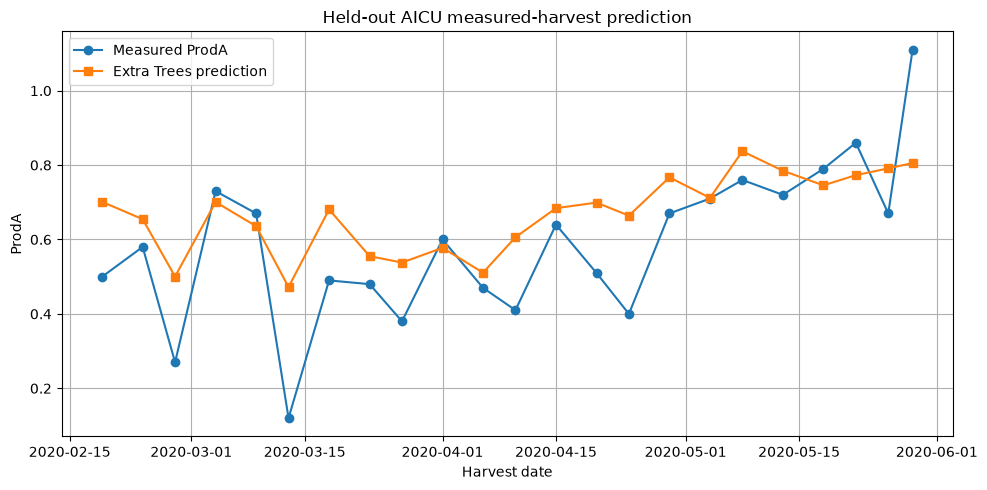

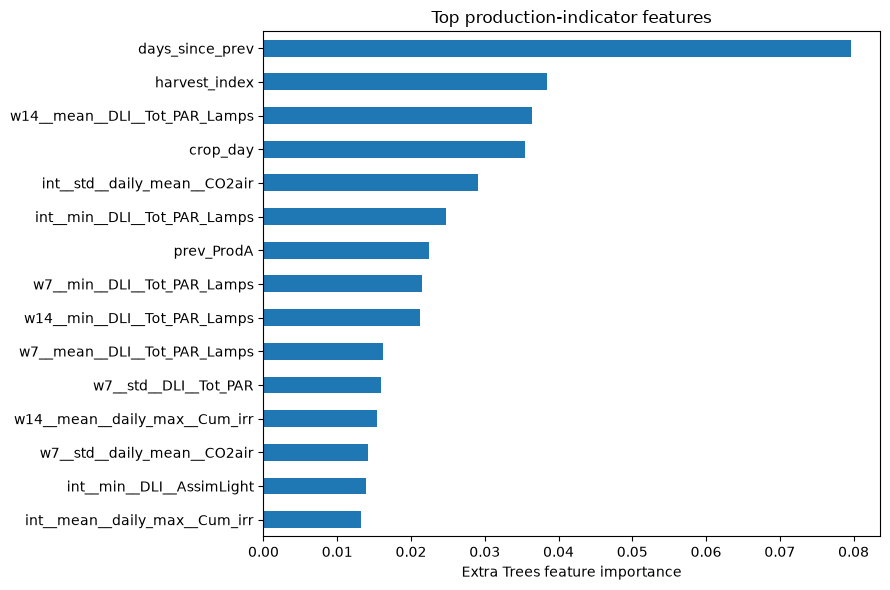

In [8]:
def ordinary_bootstrap_metrics(y, pred, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    vals = []
    y = np.asarray(y)
    pred = np.asarray(pred)
    n = len(y)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.unique(y[idx]).size < 2:
            continue
        vals.append([
            rmse_score(y[idx], pred[idx]),
            mean_absolute_error(y[idx], pred[idx]),
            r2_score(y[idx], pred[idx]),
        ])
    arr = np.asarray(vals)
    return pd.DataFrame({
        "metric": ["RMSE", "MAE", "R2"],
        "lower_95": np.percentile(arr, 2.5, axis=0),
        "upper_95": np.percentile(arr, 97.5, axis=0),
    })

prod_ci = ordinary_bootstrap_metrics(test_prod["ProdA"], prod_pred)
display(prod_ci)
prod_ci.to_csv(TABLE_DIR / "production_bootstrap_ci.csv", index=False)

plt.figure(figsize=(10, 5))
plt.plot(test_prod["harvest_date"], test_prod["ProdA"], "o-", label="Measured ProdA")
plt.plot(test_prod["harvest_date"], prod_pred, "s-", label=f"{SELECTED_PRODUCTION_MODEL} prediction")
plt.xlabel("Harvest date")
plt.ylabel("ProdA")
plt.grid()
plt.title("Held-out AICU measured-harvest prediction")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_prod_measured_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

# Use native tree importance when available; otherwise use held-out permutation importance.
final_estimator = prod_model.named_steps["model"]
if hasattr(final_estimator, "feature_importances_"):
    prod_importance = pd.Series(
        final_estimator.feature_importances_, index=PROD_FEATURES, name="importance"
    )
    importance_label = f"{SELECTED_PRODUCTION_MODEL} feature importance"
else:
    perm = permutation_importance(
        prod_model,
        test_prod[PROD_FEATURES],
        test_prod["ProdA"],
        n_repeats=30,
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE,
    )
    prod_importance = pd.Series(perm.importances_mean, index=PROD_FEATURES, name="importance")
    importance_label = "Held-out permutation importance"

prod_importance = prod_importance.sort_values(ascending=False)
prod_importance.to_csv(TABLE_DIR / "production_feature_importance.csv")
feature_importance = prod_importance.head(15)
plt.figure(figsize=(9, 6))
feature_importance.sort_values().plot(kind="barh")
plt.xlabel(importance_label)
plt.title("Top production-indicator features")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_prod_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Task B — 12-hour EC and pH forecasting

### 5.1 Physical quality control and causal hourly preparation

The quality-control limits below are deliberately broad and serve only to remove clear sensor startup or fault excursions. They are not crop setpoints:

- EC: 0.5–12 mS/cm
- pH: 3.0–8.5

Selected variables are aggregated by hourly median. Feature histories use past-only forward filling for gaps of at most three hours. Current and future EC/pH targets remain from the unfilled hourly median series; therefore, no synthetic or future-informed target values are introduced.


In [9]:
EC_COL_CANDIDATES = ["EC_drain_PC", "EC drain", "drain EC"]
PH_COL_CANDIDATES = ["pH_drain_PC", "pH drain", "drain pH"]


def numeric_available(df: pd.DataFrame, c: str, minimum: int = 100) -> bool:
    return c in df.columns and pd.to_numeric(df[c], errors="coerce").notna().sum() > minimum


def select_common_hourly_columns() -> list[str]:
    """Select hourly source variables using training-compartment schemas only."""
    terms = ["Tair", "Rhair", "CO2air", "Tot_PAR", "PAR", "HumDef", "EC_drain", "pH_drain", "Cum_irr"]
    common = {
        c for c in raw_climate[TRAIN_TEAMS[0]].columns
        if c != "timestamp"
        and any(t.lower() in c.lower() for t in terms)
        and numeric_available(raw_climate[TRAIN_TEAMS[0]], c)
    }
    for team in TRAIN_TEAMS[1:]:
        common &= {
            c for c in raw_climate[team].columns
            if c != "timestamp"
            and any(t.lower() in c.lower() for t in terms)
            and numeric_available(raw_climate[team], c)
        }
    selected = sorted(common)
    missing_in_test = [c for c in selected if c not in raw_climate[TEST_TEAM].columns]
    if missing_in_test:
        raise KeyError(f"Training-selected hourly variables missing from AICU: {missing_in_test}")
    return selected


hourly_source_cols = select_common_hourly_columns()
print("Training-selected hourly source columns:", hourly_source_cols)


def hourly_quality_control(team: str):
    df = raw_climate[team][["timestamp"] + hourly_source_cols].copy()
    for c in hourly_source_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    ec_col = find_column(df, EC_COL_CANDIDATES)
    ph_col = find_column(df, PH_COL_CANDIDATES)
    ec_bad = (~df[ec_col].between(0.5, 12.0)) & df[ec_col].notna()
    ph_bad = (~df[ph_col].between(3.0, 8.5)) & df[ph_col].notna()
    df.loc[ec_bad, ec_col] = np.nan
    df.loc[ph_bad, ph_col] = np.nan

    # The observed table is the only source of current/future targets.
    observed = df.set_index("timestamp").resample("1h").median()

    # Feature histories may carry the last valid observation forward for no more than 3 h.
    # This operation uses only information available at or before each timestamp.
    feature_ready = observed.ffill(limit=3)

    fill_counts = (feature_ready.notna() & observed.isna()).sum().sum()
    return {
        "observed": observed,
        "feature_ready": feature_ready,
        "ec_col": ec_col,
        "ph_col": ph_col,
        "EC_flagged": int(ec_bad.sum()),
        "pH_flagged": int(ph_bad.sum()),
        "past_only_filled_cells": int(fill_counts),
    }


hourly_data = {}
qc_rows = []
for team in TEAM_ORDER:
    result = hourly_quality_control(team)
    hourly_data[team] = result
    qc_rows.append({
        "team": team,
        "EC_flagged": result["EC_flagged"],
        "pH_flagged": result["pH_flagged"],
        "hourly_rows": len(result["observed"]),
        "past_only_filled_cells": result["past_only_filled_cells"],
    })

qc_table = pd.DataFrame(qc_rows)
display(qc_table)
qc_table.to_csv(TABLE_DIR / "quality_control_counts.csv", index=False)


Training-selected hourly source columns: ['CO2air', 'Cum_irr', 'EC_drain_PC', 'HumDef', 'Rhair', 'Tair', 'Tot_PAR', 'Tot_PAR_Lamps', 'pH_drain_PC']


,team,EC_flagged,pH_flagged,hourly_rows,past_only_filled_cells
0,AICU,3312,613,3985,33
1,TheAutomators,1,22,3985,16
2,Automatoes,4,0,3985,16
3,Digilog,0,0,3985,15
4,IUACAAS,1321,0,3985,22
5,Reference,679,5,3985,22


### 5.2 Lag, rolling-statistic, trend, and cyclical features

In [10]:
LAGS = [1, 3, 6, 12, 24, 48]
WINDOWS = [3, 6, 12, 24, 48]
HORIZON = 12


def rolling_slope(values):
    arr = np.asarray(values, dtype=float)
    mask = np.isfinite(arr)
    if mask.sum() < 2:
        return np.nan
    x = np.arange(len(arr))[mask]
    y = arr[mask]
    return linregress(x, y).slope


def build_hourly_features(team: str) -> pd.DataFrame:
    observed = hourly_data[team]["observed"].copy()
    h = hourly_data[team]["feature_ready"].copy()
    ec_col = hourly_data[team]["ec_col"]
    ph_col = hourly_data[team]["ph_col"]

    feat = h.copy()
    feat["hour_sin"] = np.sin(2 * np.pi * feat.index.hour / 24)
    feat["hour_cos"] = np.cos(2 * np.pi * feat.index.hour / 24)
    doy = feat.index.dayofyear
    feat["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    feat["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

    source_cols = list(h.columns)
    for c in source_cols:
        for lag in LAGS:
            feat[f"{c}__lag{lag}"] = h[c].shift(lag)
        for w in WINDOWS:
            roll = h[c].rolling(w, min_periods=w)
            feat[f"{c}__mean{w}"] = roll.mean()
            feat[f"{c}__std{w}"] = roll.std(ddof=1)
            feat[f"{c}__trend{w}"] = roll.apply(rolling_slope, raw=True)

    # Helpers are deliberately excluded from HOURLY_FEATURES below.
    # Current and future targets come from unfilled observed hourly medians.
    feat["EC_current"] = observed[ec_col]
    feat["pH_current"] = observed[ph_col]
    feat["EC_future"] = observed[ec_col].shift(-HORIZON)
    feat["pH_future"] = observed[ph_col].shift(-HORIZON)
    feat["dEC_12h"] = feat["EC_future"] - feat["EC_current"]
    feat["dpH_12h"] = feat["pH_future"] - feat["pH_current"]
    feat["team"] = team
    feat["timestamp"] = feat.index
    feat = feat.replace([np.inf, -np.inf], np.nan)
    return feat.reset_index(drop=True)


hourly_feature_frames = {team: build_hourly_features(team) for team in TEAM_ORDER}
hourly_all = pd.concat(hourly_feature_frames.values(), ignore_index=True)

TARGET_HELPERS = [
    "team", "timestamp", "EC_current", "pH_current",
    "EC_future", "pH_future", "dEC_12h", "dpH_12h",
]
HOURLY_FEATURES = [c for c in hourly_all.columns if c not in TARGET_HELPERS]

# Duplicate current aliases are not included in HOURLY_FEATURES.
assert "EC_current" not in HOURLY_FEATURES and "pH_current" not in HOURLY_FEATURES
assert len(HOURLY_FEATURES) == len(set(HOURLY_FEATURES))

# Require observed current/future targets and complete causal feature histories.
hourly_complete = hourly_all.dropna(
    subset=HOURLY_FEATURES + ["EC_current", "pH_current", "EC_future", "pH_future", "dEC_12h", "dpH_12h"]
).copy()

hourly_sample_audit = (
    hourly_complete.groupby("team")
    .size()
    .rename("usable_12h_samples")
    .reindex(TEAM_ORDER, fill_value=0)
    .reset_index()
)
display(hourly_sample_audit)
print("Predictors:", len(HOURLY_FEATURES))
hourly_sample_audit.to_csv(TABLE_DIR / "hourly_sample_audit.csv", index=False)


,team,usable_12h_samples
0,AICU,3538
1,TheAutomators,3922
2,Automatoes,3922
3,Digilog,3922
4,IUACAAS,3693
5,Reference,3755


Predictors: 202


### 5.3 Leave-one-team-out selection of Ridge regularization

In [11]:
def ridge_pipeline(alpha: float) -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=alpha)),
    ])


def hgb_pipeline() -> Pipeline:
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            learning_rate=0.05,
            max_iter=300,
            max_leaf_nodes=31,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        )),
    ])


ALPHAS = [0.001, 0.01, 0.1, 1, 3, 10, 30, 100, 300]


def leave_one_team_out_ridge_alpha(target: str, current_col: str, future_col: str):
    rows = []
    train_pool = hourly_complete[hourly_complete.team.isin(TRAIN_TEAMS)]
    for alpha in ALPHAS:
        for val_team in TRAIN_TEAMS:
            tr = train_pool[train_pool.team != val_team]
            va = train_pool[train_pool.team == val_team]
            mdl = ridge_pipeline(alpha).fit(tr[HOURLY_FEATURES], tr[target])
            pred_abs = va[current_col].to_numpy() + mdl.predict(va[HOURLY_FEATURES])
            true_abs = va[future_col].to_numpy()
            persistence = va[current_col].to_numpy()
            rows.append({
                "alpha": alpha,
                "validation_team": val_team,
                **metrics(true_abs, pred_abs),
                "Persistence_RMSE": rmse_score(true_abs, persistence),
            })

    scores = pd.DataFrame(rows)
    summary = (
        scores.groupby("alpha")
        .agg(
            mean_RMSE=("RMSE", "mean"),
            sd_RMSE=("RMSE", "std"),
            mean_MAE=("MAE", "mean"),
            mean_R2=("R2", "mean"),
        )
        .reset_index()
        .sort_values(["mean_RMSE", "sd_RMSE"])
    )

    # Near-tie rule: when mean RMSE differs by no more than 0.1% from the
    # minimum, choose the larger alpha for better coefficient stability.
    # This avoids selecting a much more regularized model merely because
    # between-compartment fold variability is large.
    best = summary.iloc[0]
    tolerance = float(best["mean_RMSE"]) * 0.001
    eligible = summary[summary["mean_RMSE"] <= float(best["mean_RMSE"]) + tolerance]
    selected_alpha = float(eligible["alpha"].max())
    return scores, summary, selected_alpha


ec_cv, ec_summary, EC_ALPHA = leave_one_team_out_ridge_alpha(
    "dEC_12h", "EC_current", "EC_future"
)
ph_cv, ph_summary, PH_ALPHA = leave_one_team_out_ridge_alpha(
    "dpH_12h", "pH_current", "pH_future"
)

print("EC Ridge alpha summary")
display(ec_summary)
print("pH Ridge alpha summary")
display(ph_summary)
print("Selected EC alpha by 0.1% near-tie rule:", EC_ALPHA)
print("Selected pH alpha by 0.1% near-tie rule:", PH_ALPHA)

ec_cv.to_csv(TABLE_DIR / "ec_ridge_alpha_folds.csv", index=False)
ph_cv.to_csv(TABLE_DIR / "ph_ridge_alpha_folds.csv", index=False)
ec_summary.to_csv(TABLE_DIR / "ec_ridge_alpha_summary.csv", index=False)
ph_summary.to_csv(TABLE_DIR / "ph_ridge_alpha_summary.csv", index=False)


def compare_hourly_families(target: str, current_col: str, future_col: str, ridge_alpha: float):
    rows = []
    train_pool = hourly_complete[hourly_complete.team.isin(TRAIN_TEAMS)]
    candidates = {
        "Ridge": ridge_pipeline(ridge_alpha),
        "Histogram Gradient Boosting": hgb_pipeline(),
    }
    for family, template in candidates.items():
        for val_team in TRAIN_TEAMS:
            tr = train_pool[train_pool.team != val_team]
            va = train_pool[train_pool.team == val_team]
            mdl = clone(template).fit(tr[HOURLY_FEATURES], tr[target])
            pred_abs = va[current_col].to_numpy() + mdl.predict(va[HOURLY_FEATURES])
            rows.append({
                "Model": family,
                "validation_team": val_team,
                **metrics(va[future_col], pred_abs),
            })
    folds = pd.DataFrame(rows)
    summary = (
        folds.groupby("Model")
        .agg(mean_RMSE=("RMSE", "mean"), sd_RMSE=("RMSE", "std"), mean_MAE=("MAE", "mean"), mean_R2=("R2", "mean"))
        .reset_index()
        .sort_values(["mean_RMSE", "sd_RMSE"])
        .reset_index(drop=True)
    )

    # Ridge is retained for transparent, compact edge deployment when its
    # mean RMSE is within 1% of the best tested family. Otherwise, select
    # the empirically best family and require the manuscript to be updated.
    best = summary.iloc[0]
    ridge_row = summary[summary["Model"] == "Ridge"].iloc[0]
    if float(ridge_row["mean_RMSE"]) <= float(best["mean_RMSE"]) * 1.01:
        selected = "Ridge"
    else:
        selected = str(best["Model"])
    return folds, summary, selected


ec_family_folds, ec_family_summary, EC_MODEL_FAMILY = compare_hourly_families(
    "dEC_12h", "EC_current", "EC_future", EC_ALPHA
)
ph_family_folds, ph_family_summary, PH_MODEL_FAMILY = compare_hourly_families(
    "dpH_12h", "pH_current", "pH_future", PH_ALPHA
)

print("EC family comparison")
display(ec_family_summary)
print("pH family comparison")
display(ph_family_summary)
print("Selected EC family:", EC_MODEL_FAMILY)
print("Selected pH family:", PH_MODEL_FAMILY)

ec_family_folds.to_csv(TABLE_DIR / "ec_model_family_folds.csv", index=False)
ph_family_folds.to_csv(TABLE_DIR / "ph_model_family_folds.csv", index=False)
ec_family_summary.to_csv(TABLE_DIR / "ec_model_family_summary.csv", index=False)
ph_family_summary.to_csv(TABLE_DIR / "ph_model_family_summary.csv", index=False)

if EC_MODEL_FAMILY != "Ridge" or PH_MODEL_FAMILY != "Ridge":
    print(
        "MANUSCRIPT WARNING: at least one corrected nutrient model is not Ridge. "
        "Update the methodology, results, interpretation figure, artifact sizes, and abstract."
    )


EC Ridge alpha summary


,alpha,mean_RMSE,sd_RMSE,mean_MAE,mean_R2
6,30.000,0.320949,0.078790,0.194535,0.921259
5,10.000,0.321090,0.079015,0.194643,0.921161
4,3.000,0.321429,0.078935,0.194994,0.920934
3,1.000,0.321657,0.078779,0.195300,0.920779
7,100.000,0.321666,0.077911,0.195339,0.920930
2,0.100,0.321850,0.078560,0.195612,0.920698
1,0.010,0.321941,0.078507,0.195718,0.920663
0,0.001,0.321961,0.078499,0.195736,0.920652
8,300.000,0.323398,0.076385,0.196744,0.920109


pH Ridge alpha summary


,alpha,mean_RMSE,sd_RMSE,mean_MAE,mean_R2
0,0.001,0.100351,0.033437,0.060758,0.982239
1,0.010,0.100368,0.033448,0.060769,0.982235
2,0.100,0.100555,0.033560,0.060912,0.982185
3,1.000,0.101156,0.033729,0.061409,0.982013
4,3.000,0.101294,0.033705,0.061566,0.981984
5,10.000,0.101435,0.033647,0.061782,0.981967
6,30.000,0.102242,0.033801,0.062616,0.981728
7,100.000,0.104832,0.034479,0.065043,0.980861
8,300.000,0.107852,0.035005,0.067817,0.979833


Selected EC alpha by 0.1% near-tie rule: 30.0
Selected pH alpha by 0.1% near-tie rule: 0.01
EC family comparison


,Model,mean_RMSE,sd_RMSE,mean_MAE,mean_R2
0,Ridge,0.320949,0.07879,0.194535,0.921259
1,Histogram Gradient Boosting,0.330562,0.07691,0.204620,0.917459


pH family comparison


,Model,mean_RMSE,sd_RMSE,mean_MAE,mean_R2
0,Ridge,0.100368,0.033448,0.060769,0.982235
1,Histogram Gradient Boosting,0.107611,0.035972,0.068142,0.979911


Selected EC family: Ridge
Selected pH family: Ridge


### 5.4 Final held-out AICU evaluation

In [12]:
train_hourly = hourly_complete[hourly_complete.team.isin(TRAIN_TEAMS)].copy()
test_hourly = hourly_complete[hourly_complete.team == TEST_TEAM].copy()


def make_selected_hourly_model(family: str, alpha: float) -> Pipeline:
    if family == "Ridge":
        return ridge_pipeline(alpha)
    if family == "Histogram Gradient Boosting":
        return hgb_pipeline()
    raise ValueError(f"Unsupported model family: {family}")


ec_model = make_selected_hourly_model(EC_MODEL_FAMILY, EC_ALPHA).fit(
    train_hourly[HOURLY_FEATURES], train_hourly["dEC_12h"]
)
ph_model = make_selected_hourly_model(PH_MODEL_FAMILY, PH_ALPHA).fit(
    train_hourly[HOURLY_FEATURES], train_hourly["dpH_12h"]
)

ec_pred = test_hourly["EC_current"].to_numpy() + ec_model.predict(test_hourly[HOURLY_FEATURES])
ph_pred = test_hourly["pH_current"].to_numpy() + ph_model.predict(test_hourly[HOURLY_FEATURES])

ec_true = test_hourly["EC_future"].to_numpy()
ph_true = test_hourly["pH_future"].to_numpy()
ec_persist = test_hourly["EC_current"].to_numpy()
ph_persist = test_hourly["pH_current"].to_numpy()


def result_row(target, model_true, model_pred, persistence, family):
    m = metrics(model_true, model_pred)
    p = metrics(model_true, persistence)
    return {
        "Target": target,
        "Model": family,
        "Model_RMSE": m["RMSE"],
        "Persistence_RMSE": p["RMSE"],
        "Model_MAE": m["MAE"],
        "Persistence_MAE": p["MAE"],
        "Model_R2": m["R2"],
        "Persistence_R2": p["R2"],
        "RMSE_reduction_pct": 100 * (p["RMSE"] - m["RMSE"]) / p["RMSE"],
        "MAE_reduction_pct": 100 * (p["MAE"] - m["MAE"]) / p["MAE"],
    }

heldout_results = pd.DataFrame([
    result_row("EC, held-out AICU", ec_true, ec_pred, ec_persist, EC_MODEL_FAMILY),
    result_row("pH, held-out AICU", ph_true, ph_pred, ph_persist, PH_MODEL_FAMILY),
])
display(heldout_results)
heldout_results.to_csv(TABLE_DIR / "ec_ph_heldout_results.csv", index=False)


,Target,Model,Model_RMSE,Persistence_RMSE,Model_MAE,Persistence_MAE,Model_R2,Persistence_R2,RMSE_reduction_pct,MAE_reduction_pct
0,"EC, held-out AICU",Ridge,0.289453,0.422514,0.187588,0.316523,0.836868,0.652410,31.492773,40.734727
1,"pH, held-out AICU",Ridge,0.189000,0.286697,0.089593,0.160254,0.981393,0.957184,34.076783,44.093511


### 5.5 Moving-block bootstrap confidence intervals

In [13]:
def moving_block_bootstrap(y, pred, block=24, n_boot=3000, seed=42):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    pred = np.asarray(pred)
    n = len(y)
    if n < block:
        raise ValueError(f"Test series length {n} is smaller than block length {block}.")

    values = []
    starts = np.arange(0, n - block + 1)
    for _ in range(n_boot):
        idx = []
        while len(idx) < n:
            s = int(rng.choice(starts))
            idx.extend(range(s, s + block))
        idx = np.asarray(idx[:n])
        if np.unique(y[idx]).size < 2:
            continue
        values.append([
            rmse_score(y[idx], pred[idx]),
            mean_absolute_error(y[idx], pred[idx]),
            r2_score(y[idx], pred[idx]),
        ])

    arr = np.asarray(values)
    return {
        "RMSE_95": [float(x) for x in np.percentile(arr[:, 0], [2.5, 97.5])],
        "MAE_95": [float(x) for x in np.percentile(arr[:, 1], [2.5, 97.5])],
        "R2_95": [float(x) for x in np.percentile(arr[:, 2], [2.5, 97.5])],
        "block_hours": block,
        "successful_resamples": int(len(arr)),
    }


ec_ci = moving_block_bootstrap(ec_true, ec_pred)
ph_ci = moving_block_bootstrap(ph_true, ph_pred)
print("EC CI:", ec_ci)
print("pH CI:", ph_ci)
(TABLE_DIR / "block_bootstrap_ci.json").write_text(
    json.dumps({"EC": ec_ci, "pH": ph_ci}, indent=2)
)


EC CI: {'RMSE_95': [0.22675957750878598, 0.3738933269654784], 'MAE_95': [0.1670588318568468, 0.21031361538060556], 'R2_95': [0.7273384889593084, 0.9026174013765492], 'block_hours': 24, 'successful_resamples': 3000}
pH CI: {'RMSE_95': [0.12646838989658096, 0.2522329606167156], 'MAE_95': [0.07184836079916224, 0.10984981648178443], 'R2_95': [0.9658433761561324, 0.9916899265287648], 'block_hours': 24, 'successful_resamples': 3000}


593

### 5.6 Forecast and baseline figures

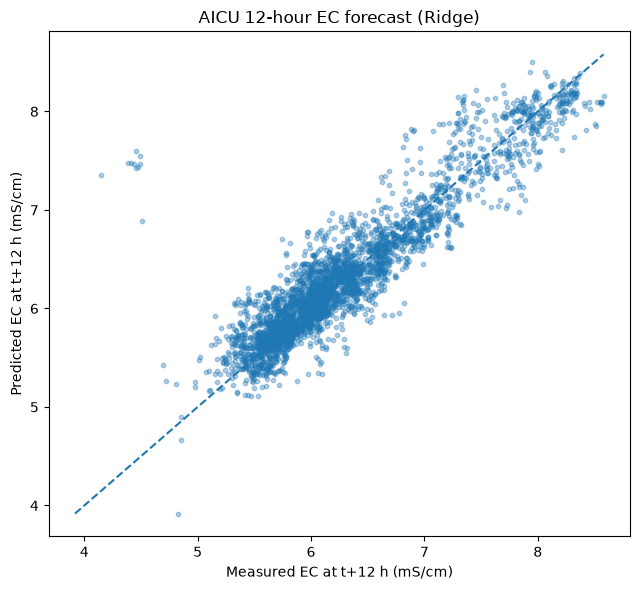

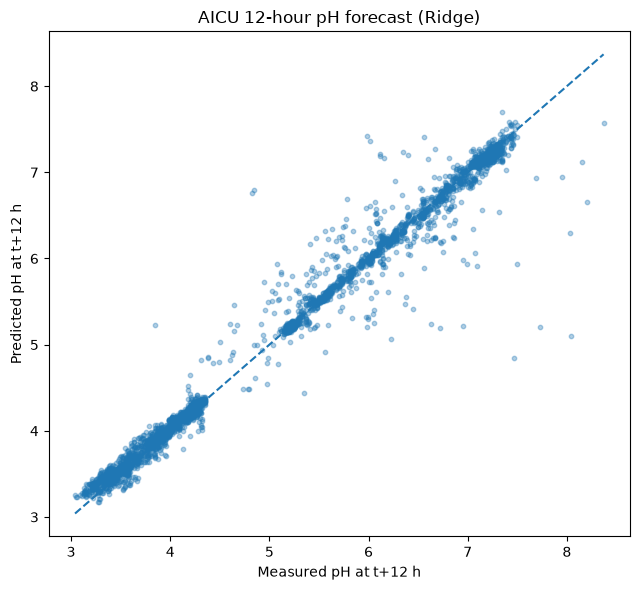

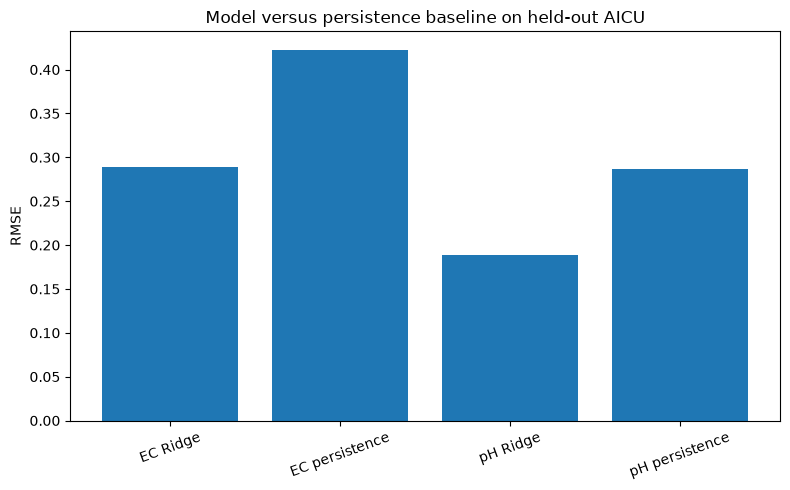

In [14]:
def scatter_forecast(y, pred, title, xlabel, ylabel, filename):
    plt.figure(figsize=(6.5, 6))
    plt.scatter(y, pred, s=10, alpha=0.35)
    lo = min(np.nanmin(y), np.nanmin(pred))
    hi = max(np.nanmax(y), np.nanmax(pred))
    plt.plot([lo, hi], [lo, hi], "--", linewidth=1.5)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()

scatter_forecast(
    ec_true, ec_pred,
    f"AICU 12-hour EC forecast ({EC_MODEL_FAMILY})",
    "Measured EC at t+12 h (mS/cm)",
    "Predicted EC at t+12 h (mS/cm)",
    "fig_ec_forecast.png",
)
scatter_forecast(
    ph_true, ph_pred,
    f"AICU 12-hour pH forecast ({PH_MODEL_FAMILY})",
    "Measured pH at t+12 h",
    "Predicted pH at t+12 h",
    "fig_ph_forecast.png",
)

comparison = pd.DataFrame({
    "Method": [f"EC {EC_MODEL_FAMILY}", "EC persistence", f"pH {PH_MODEL_FAMILY}", "pH persistence"],
    "RMSE": [
        rmse_score(ec_true, ec_pred),
        rmse_score(ec_true, ec_persist),
        rmse_score(ph_true, ph_pred),
        rmse_score(ph_true, ph_persist),
    ],
})
comparison.to_csv(TABLE_DIR / "model_vs_persistence_rmse.csv", index=False)
plt.figure(figsize=(8, 5))
plt.bar(comparison["Method"], comparison["RMSE"])
plt.ylabel("RMSE")
plt.title("Model versus persistence baseline on held-out AICU")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_model_vs_persistence.png", dpi=300, bbox_inches="tight")
plt.show()


### 5.7 Standardized Ridge coefficients

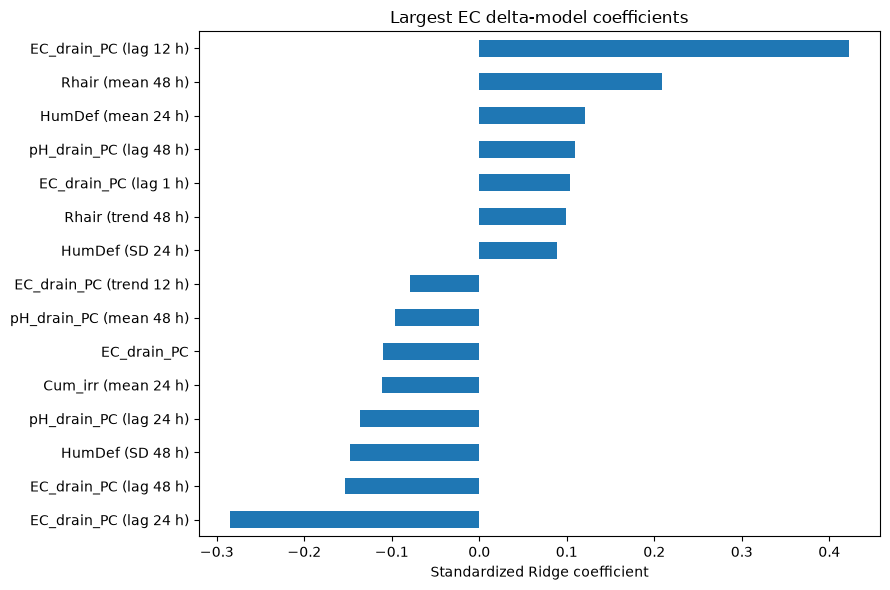

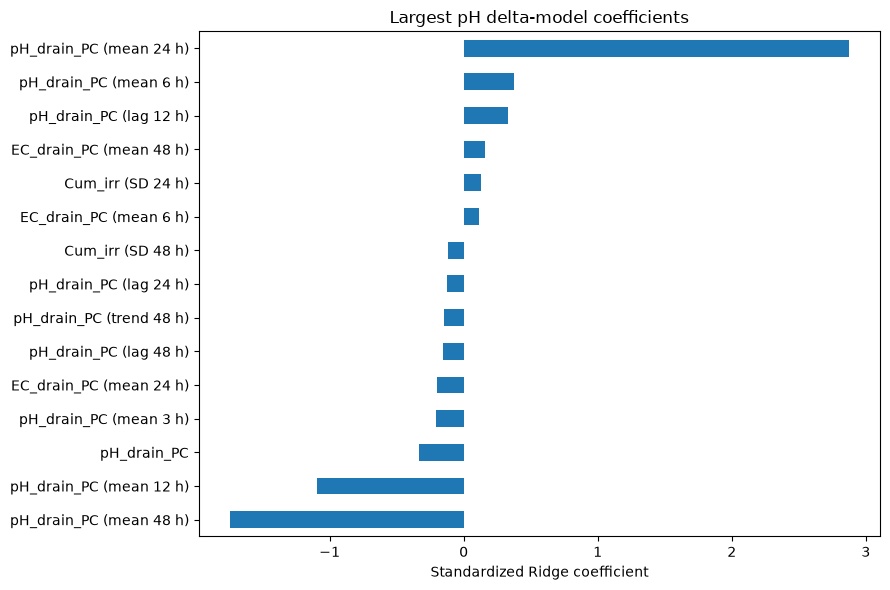

In [15]:
def clean_feature_label(name: str) -> str:
    label = name.replace("__", "_")
    label = re.sub(r"_lag(\d+)$", r" (lag \1 h)", label)
    label = re.sub(r"_mean(\d+)$", r" (mean \1 h)", label)
    label = re.sub(r"_std(\d+)$", r" (SD \1 h)", label)
    label = re.sub(r"_trend(\d+)$", r" (trend \1 h)", label)
    return label


def model_interpretation_values(model: Pipeline, X: pd.DataFrame, y_delta: pd.Series, family: str) -> pd.Series:
    estimator = model.named_steps["model"]
    if family == "Ridge":
        return pd.Series(estimator.coef_, index=HOURLY_FEATURES, name="standardized_coefficient")

    # For nonlinear alternatives, use held-out permutation importance on the delta target.
    perm = permutation_importance(
        model,
        X,
        y_delta,
        n_repeats=20,
        scoring="neg_root_mean_squared_error",
        random_state=RANDOM_STATE,
    )
    return pd.Series(perm.importances_mean, index=HOURLY_FEATURES, name="permutation_importance")


ec_interpretation = model_interpretation_values(
    ec_model, test_hourly[HOURLY_FEATURES], test_hourly["dEC_12h"], EC_MODEL_FAMILY
).sort_values(key=np.abs, ascending=False)
ph_interpretation = model_interpretation_values(
    ph_model, test_hourly[HOURLY_FEATURES], test_hourly["dpH_12h"], PH_MODEL_FAMILY
).sort_values(key=np.abs, ascending=False)

ec_interpretation.to_csv(TABLE_DIR / "ec_model_interpretation.csv")
ph_interpretation.to_csv(TABLE_DIR / "ph_model_interpretation.csv")

for target_name, values, family, filename in [
    ("EC", ec_interpretation.head(15), EC_MODEL_FAMILY, "fig_ec_coefficients.png"),
    ("pH", ph_interpretation.head(15), PH_MODEL_FAMILY, "fig_ph_coefficients.png"),
]:
    plotted = values.copy()
    plotted.index = [clean_feature_label(x) for x in plotted.index]
    plt.figure(figsize=(9, 6))
    plotted.sort_values().plot(kind="barh")
    if family == "Ridge":
        plt.xlabel("Standardized Ridge coefficient")
        plt.title(f"Largest {target_name} delta-model coefficients")
    else:
        plt.xlabel("Held-out permutation importance")
        plt.title(f"Largest {target_name} delta-model permutation importances")
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


## 6. Export model artifacts, metadata, and prediction files

In [16]:
# Generic names prevent stale model-family labels in filenames.
prod_model_path = MODEL_DIR / "production_model.joblib"
ec_model_path = MODEL_DIR / "ec_12h_model.joblib"
ph_model_path = MODEL_DIR / "ph_12h_model.joblib"
joblib.dump(prod_model, prod_model_path)
joblib.dump(ec_model, ec_model_path)
joblib.dump(ph_model, ph_model_path)

metadata = {
    "dataset": "Autonomous Greenhouse Challenge, Second Edition (2019)",
    "dataset_doi": "10.4121/uuid:88d22c60-21b3-4ea8-90db-20249a5be2a7",
    "random_state": RANDOM_STATE,
    "training_teams": TRAIN_TEAMS,
    "held_out_test_team": TEST_TEAM,
    "production_model_family": SELECTED_PRODUCTION_MODEL,
    "ec_model_family": EC_MODEL_FAMILY,
    "ph_model_family": PH_MODEL_FAMILY,
    "production_features": PROD_FEATURES,
    "hourly_features": HOURLY_FEATURES,
    "production_feature_count": len(PROD_FEATURES),
    "hourly_feature_count": len(HOURLY_FEATURES),
    "forecast_horizon_hours": HORIZON,
    "gap_policy": "past-only forward fill, maximum 3 hours, feature histories only",
    "target_policy": "current and future EC/pH retained only from unfilled hourly medians",
    "ec_alpha": EC_ALPHA if EC_MODEL_FAMILY == "Ridge" else None,
    "ph_alpha": PH_ALPHA if PH_MODEL_FAMILY == "Ridge" else None,
    "artifact_sizes_bytes": {
        "production": prod_model_path.stat().st_size,
        "EC": ec_model_path.stat().st_size,
        "pH": ph_model_path.stat().st_size,
    },
    "limitations": [
        "Models are trained on cherry-tomato greenhouse data.",
        "Models are not validated on the deployed lettuce NFT crop.",
        "Raspberry Pi latency and memory must be measured on the target device.",
        "Automatic dosing requires local pump, solution, mixing-delay, and crop validation.",
    ],
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

pd.DataFrame({
    "timestamp": test_hourly["timestamp"],
    "EC_measured_t12": ec_true,
    "EC_predicted_t12": ec_pred,
    "EC_persistence": ec_persist,
    "pH_measured_t12": ph_true,
    "pH_predicted_t12": ph_pred,
    "pH_persistence": ph_persist,
}).to_csv(OUTPUT_DIR / "aicu_ec_ph_predictions.csv", index=False)

pd.DataFrame({
    "harvest_date": test_prod["harvest_date"],
    "ProdA_measured": test_prod["ProdA"],
    "ProdA_predicted": prod_pred,
}).to_csv(OUTPUT_DIR / "aicu_production_predictions.csv", index=False)

# Exact values for manuscript cross-checking.
prod_model_row = prod_results[prod_results["Method"] == SELECTED_PRODUCTION_MODEL].iloc[0]
strongest_baseline = prod_results[prod_results["Method"] != SELECTED_PRODUCTION_MODEL].sort_values("RMSE").iloc[0]
summary_rows = [
    {"item": "production_model", "value": SELECTED_PRODUCTION_MODEL},
    {"item": "production_train_events", "value": int(len(train_prod))},
    {"item": "production_test_events", "value": int(len(test_prod))},
    {"item": "production_predictors", "value": int(len(PROD_FEATURES))},
    {"item": "production_RMSE", "value": float(prod_model_row["RMSE"])},
    {"item": "production_MAE", "value": float(prod_model_row["MAE"])},
    {"item": "production_R2", "value": float(prod_model_row["R2"])},
    {"item": "production_best_baseline", "value": str(strongest_baseline["Method"])},
    {"item": "production_RMSE_reduction_pct", "value": float(100*(strongest_baseline["RMSE"]-prod_model_row["RMSE"])/strongest_baseline["RMSE"])},
    {"item": "production_MAE_reduction_pct", "value": float(100*(strongest_baseline["MAE"]-prod_model_row["MAE"])/strongest_baseline["MAE"])},
    {"item": "hourly_predictors", "value": int(len(HOURLY_FEATURES))},
    {"item": "hourly_train_samples", "value": int(len(train_hourly))},
    {"item": "hourly_test_samples", "value": int(len(test_hourly))},
    {"item": "EC_model_family", "value": EC_MODEL_FAMILY},
    {"item": "EC_alpha", "value": EC_ALPHA if EC_MODEL_FAMILY == "Ridge" else "not applicable"},
    {"item": "pH_model_family", "value": PH_MODEL_FAMILY},
    {"item": "pH_alpha", "value": PH_ALPHA if PH_MODEL_FAMILY == "Ridge" else "not applicable"},
]
for _, row in heldout_results.iterrows():
    prefix = "EC" if str(row["Target"]).startswith("EC") else "pH"
    for key in ["Model_RMSE", "Persistence_RMSE", "Model_MAE", "Persistence_MAE", "Model_R2", "Persistence_R2", "RMSE_reduction_pct", "MAE_reduction_pct"]:
        summary_rows.append({"item": f"{prefix}_{key}", "value": float(row[key])})

paper_summary = pd.DataFrame(summary_rows)
display(paper_summary)
paper_summary.to_csv(TABLE_DIR / "MANUSCRIPT_EXACT_VALUES.csv", index=False)
(TABLE_DIR / "MANUSCRIPT_EXACT_VALUES.json").write_text(
    json.dumps(dict(zip(paper_summary["item"], paper_summary["value"])), indent=2, default=str)
)

print("Exported files:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(p.relative_to(OUTPUT_DIR), p.stat().st_size)


,item,value
0,production_model,Extra Trees
1,production_train_events,110
2,production_test_events,23
3,production_predictors,205
4,production_RMSE,0.158356
5,production_MAE,0.126107
6,production_R2,0.406536
7,production_best_baseline,Previous-3 mean
8,production_RMSE_reduction_pct,16.044
9,production_MAE_reduction_pct,13.847797


Exported files:
aicu_ec_ph_predictions.csv 323175
aicu_production_predictions.csv 867
figures\fig_ec_coefficients.png 156640
figures\fig_ec_forecast.png 462814
figures\fig_model_vs_persistence.png 83483
figures\fig_ph_coefficients.png 157485
figures\fig_ph_forecast.png 285335
figures\fig_prod_feature_importance.png 167653
figures\fig_prod_measured_predicted.png 210581
models\ec_12h_model.joblib 13129
models\metadata.json 14041
models\ph_12h_model.joblib 13129
models\production_model.joblib 4278951
tables\block_bootstrap_ci.json 626
tables\ec_model_family_folds.csv 901
tables\ec_model_family_summary.csv 234
tables\ec_model_interpretation.csv 7696
tables\ec_ph_heldout_results.csv 488
tables\ec_ridge_alpha_folds.csv 4251
tables\ec_ridge_alpha_summary.csv 801
tables\hourly_sample_audit.csv 117
tables\MANUSCRIPT_EXACT_VALUES.csv 1125
tables\MANUSCRIPT_EXACT_VALUES.json 1322
tables\model_vs_persistence_rmse.csv 144
tables\ph_model_family_folds.csv 905
tables\ph_model_family_summary.csv 236
t

## 7. Reproducible benchmarking

The following cell can be run on either a development computer or the Raspberry Pi. It records the platform explicitly, so host measurements cannot be mistaken for Raspberry Pi performance. Leave `RUN_BENCHMARK = False` in the publication notebook until the intended device is available.


In [17]:
RUN_BENCHMARK = False
EXPECTED_DEVICE = "Raspberry Pi"  # Change only when intentionally benchmarking another device.

try:
    import psutil
except ImportError:
    psutil = None


def benchmark_single_sample(model, X_row: pd.DataFrame, repeats: int = 1000, warmup: int = 50):
    for _ in range(warmup):
        model.predict(X_row)

    process = psutil.Process(os.getpid()) if psutil else None
    rss_before = process.memory_info().rss if process else np.nan

    tracemalloc.start()
    timings = []
    cpu_samples = []
    for _ in range(repeats):
        if process:
            process.cpu_percent(interval=None)
        t0 = time.perf_counter_ns()
        model.predict(X_row)
        timings.append((time.perf_counter_ns() - t0) / 1e6)
        if process:
            cpu_samples.append(process.cpu_percent(interval=None))
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    rss_after = process.memory_info().rss if process else np.nan
    return {
        "platform": platform.platform(),
        "machine": platform.machine(),
        "processor": platform.processor(),
        "python": platform.python_version(),
        "repeats": repeats,
        "median_ms": float(np.median(timings)),
        "mean_ms": float(np.mean(timings)),
        "p95_ms": float(np.percentile(timings, 95)),
        "max_ms": float(np.max(timings)),
        "rss_before_MB": float(rss_before / 1e6) if np.isfinite(rss_before) else np.nan,
        "rss_after_MB": float(rss_after / 1e6) if np.isfinite(rss_after) else np.nan,
        "python_peak_alloc_MB": float(peak / 1e6),
        "mean_cpu_percent": float(np.mean(cpu_samples)) if cpu_samples else np.nan,
    }


if RUN_BENCHMARK:
    benchmark_rows = [
        {"artifact": "Production", **benchmark_single_sample(prod_model, test_prod[PROD_FEATURES].iloc[[0]])},
        {"artifact": "EC", **benchmark_single_sample(ec_model, test_hourly[HOURLY_FEATURES].iloc[[0]])},
        {"artifact": "pH", **benchmark_single_sample(ph_model, test_hourly[HOURLY_FEATURES].iloc[[0]])},
    ]
    benchmark_table = pd.DataFrame(benchmark_rows)
    display(benchmark_table)

    filename = "raspberry_pi_benchmark.csv" if EXPECTED_DEVICE.lower().startswith("raspberry") else "development_host_benchmark.csv"
    benchmark_table.to_csv(TABLE_DIR / filename, index=False)

    platform_text = " ".join(benchmark_table["platform"].astype(str).tolist()).lower()
    if EXPECTED_DEVICE.lower().startswith("raspberry") and "raspberry" not in platform_text:
        print("WARNING: this does not appear to be a Raspberry Pi. Do not report it as target-device performance.")
else:
    print("Benchmark skipped. Set RUN_BENCHMARK=True on the intended device.")


Benchmark skipped. Set RUN_BENCHMARK=True on the intended device.


## 8. Interpretation and publication boundary

The resulting models should be interpreted as a **cross-greenhouse modeling and edge-integration pipeline**:

- `ProdA` is a cherry-tomato harvest-event production indicator, not lettuce yield.
- EC and pH targets originate from Autonomous Greenhouse Challenge drain measurements.
- The public dataset was collected in high-technology glasshouse compartments in the Netherlands.
- The physical HTU prototype grows lettuce in an NFT system in Jordan.
- The corrected causal preparation prevents future observations from being used in feature-gap filling and preserves observed EC/pH targets.
- Model-family and regularization choices are generated from leave-one-compartment-out results rather than manually imposed.
- The notebook establishes methodology, generalization testing, persistence baselines, uncertainty analysis, reproducible figures, and deployable artifacts; it does **not** establish crop-specific control validity for the lettuce prototype.
- The three dosing pumps may influence EC and pH through the three stock solutions, but automatic dosing requires pump-flow calibration, stock-solution documentation, mixing-delay experiments, hard safety limits, and local lettuce trials.

Before manuscript submission, copy all values from `paper2_outputs_v3/tables/MANUSCRIPT_EXACT_VALUES.csv` and confirm that the model names, sample counts, feature counts, figures, confidence intervals, and percentages match the paper exactly.
